# Text Message Sentiment Analysis with Emotion-Labeled Dataset

**Dataset:** [Emotions Dataset on Kaggle](https://www.kaggle.com/datasets/nelgiriyewithana/emotions)

**Features:**
- `text`: A string feature representing the content of the Twitter message.
- `label`: A classification label indicating the primary emotion, with values ranging from 0 to 5.

---

## Project Overview

We will use a dataset of **416,809 English Twitter messages**, each labeled with one of six emotions:

- Sadness
- Joy
- Love
- Anger
- Fear
- Surprise

Our goal is to determine which combination of **feature representation** and **classifier** best detects emotion in text. The dataset is **class-imbalanced** and contains **conflicting labels** between related emotions (e.g., joy vs. love, or fear vs. surprise), making it a useful setting for comparing how well different approaches handle ambiguous messages.

---

## Project Goal

The main goal is to identify the **best-performing combination** of feature representation and classifier for emotion detection.

**Feature Representations (5):**
1. Bag of Words
2. TF-IDF
3. Word2Vec
4. GloVe
5. Transformer-based embeddings (e.g., BERT / DistilBERT)

**Classifiers (4):**
1. Naive Bayes
2. Logistic Regression
3. SVM
4. Fine-tuned Transformer (e.g., DistilBERT)

**Evaluation Metrics:**
- Accuracy
- Macro-F1
- Per-class performance

> **Note:** Naive Bayes will only be paired with **Bag of Words** and **TF-IDF**, since it requires non-negative features and is not suited to dense word embeddings. The **fine-tuned Transformer** classifier will be evaluated as its own end-to-end pipeline (not paired with the other feature representations), since transformer models learn their own contextual embeddings internally rather than consuming precomputed features.

The best-performing model will then be used to analyze new text messages, providing a **predicted emotion** and a **probability distribution** across all six emotions.


DATA PRE PROCESSING 


The Shape Of Data Is : (416809, 3)


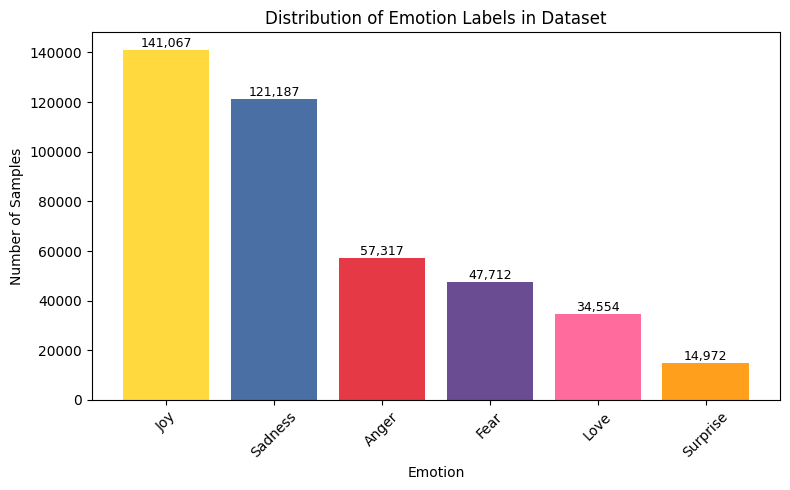


Label counts:
label
Joy         141067
Sadness     121187
Anger        57317
Fear         47712
Love         34554
Surprise     14972
Name: count, dtype: int64


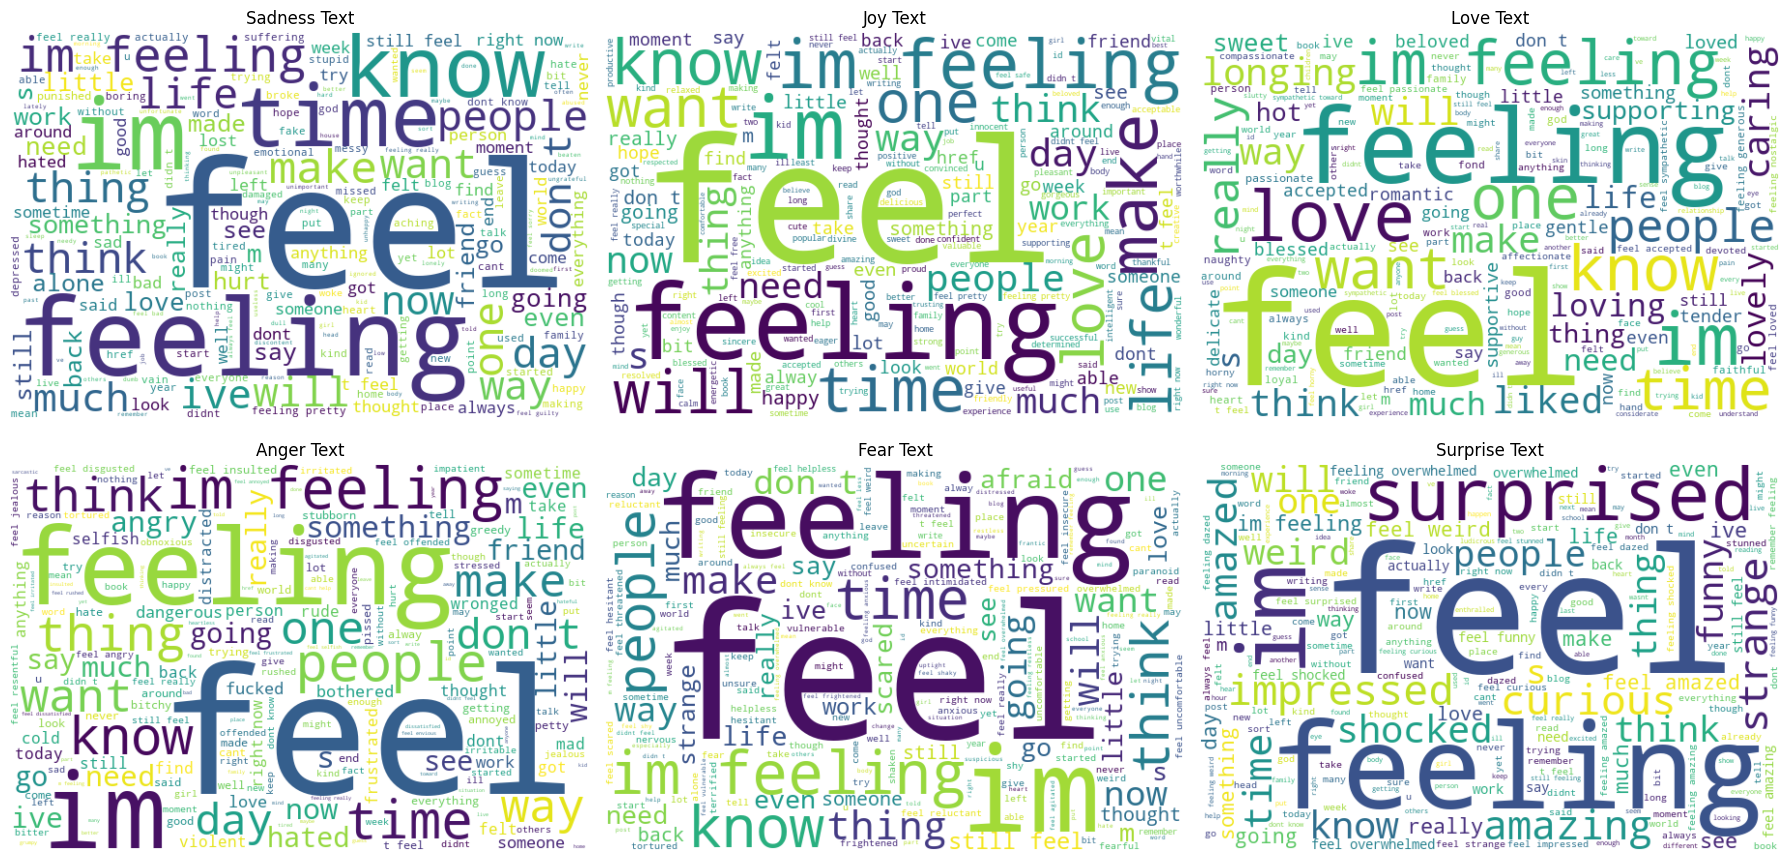

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

#Data Pre Processing
DATA_PATH = Path("text.csv")  #dataset must be named text.csv Column 0: text Column 1: label
df  = pd.read_csv(DATA_PATH)

print(f'The Shape Of Data Is : {df.shape}') #See Shape of DF

df.isnull().sum() #Checks for Null entries
df.duplicated().sum()#Checks for duplicates 
df = df.drop(columns=['Unnamed: 0'])#Removes redundant column
df.head()




#Show Data Distribution 
emotion_map = {0: 'Sadness', 1: 'Joy', 2: 'Love', 3: 'Anger', 4: 'Fear', 5: 'Surprise'}

emotion_colors = {
    0: '#4A6FA5',   # Sadness - blue
    1: '#FFD93D',   # Joy - yellow
    2: '#FF6B9D',   # Love - pink
    3: '#E63946',   # Anger - red
    4: '#6A4C93',   # Fear - purple
    5: '#FF9F1C',   # Surprise - orange
}

label_counts = df['label'].value_counts().sort_values(ascending=False)
colors = [emotion_colors[i] for i in label_counts.index]

plt.figure(figsize=(8, 5))
bars = plt.bar([emotion_map[i] for i in label_counts.index], label_counts.values, color=colors)

plt.xlabel('Emotion')
plt.ylabel('Number of Samples')
plt.title('Distribution of Emotion Labels in Dataset')
plt.xticks(rotation=45)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height, f'{height:,}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

print("\nLabel counts:")
print(label_counts.rename(index=emotion_map))

# Generate word clouds per emotion  (Found from https://www.kaggle.com/code/abdmental01/emotions-analysis-gru-94)
from wordcloud import WordCloud

def generate_wordcloud(label_value):
    text_combined = " ".join(df.loc[df['label'] == label_value, 'text'].astype(str))
    return WordCloud(width=600, height=400, background_color='white',
                      colormap='viridis').generate(text_combined)

sadness_wordcloud = generate_wordcloud(0)
joy_wordcloud = generate_wordcloud(1)
love_wordcloud = generate_wordcloud(2)
anger_wordcloud = generate_wordcloud(3)
fear_wordcloud = generate_wordcloud(4)
surprise_wordcloud = generate_wordcloud(5)

# Plot the word clouds
plt.figure(figsize=(18, 9))

plt.subplot(2, 3, 1)
plt.imshow(sadness_wordcloud, interpolation='bilinear')
plt.title('Sadness Text')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(joy_wordcloud, interpolation='bilinear')
plt.title('Joy Text')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(love_wordcloud, interpolation='bilinear')
plt.title('Love Text')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(anger_wordcloud, interpolation='bilinear')
plt.title('Anger Text')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(fear_wordcloud, interpolation='bilinear')
plt.title('Fear Text')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(surprise_wordcloud, interpolation='bilinear')
plt.title('Surprise Text')
plt.axis('off')

plt.tight_layout()
plt.show()


TF IDF: Linear Regression, Naive Bayes

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Split data: 80% train, 10% dev, 10% test
train_df, temp_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])
dev_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42, stratify=temp_df['label'])

print(f"Train size: {len(train_df)}, Dev size: {len(dev_df)}, Test size: {len(test_df)}")

# Fit TF-IDF only on training data to avoid data leakage
tfidf_vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
X_train_tfidf = tfidf_vectorizer.fit_transform(train_df['text'])
X_dev_tfidf = tfidf_vectorizer.transform(dev_df['text'])
X_test_tfidf = tfidf_vectorizer.transform(test_df['text'])

y_train = train_df['label']
y_dev = dev_df['label']
y_test = test_df['label']

print(f"TF-IDF matrix shape: {X_train_tfidf.shape}")

# ---- Naive Bayes ----
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

nb_dev_preds = nb_model.predict(X_dev_tfidf)
nb_dev_preds = nb_model.predict(X_dev_tfidf)
print("Naive Bayes (Dev Set):")
print(f"  Accuracy: {accuracy_score(y_dev, nb_dev_preds):.4f}")
print(f"  Macro-F1: {f1_score(y_dev, nb_dev_preds, average='macro'):.4f}")

# Per-class performance
print("\nNaive Bayes Classification Report (Dev):")
print(classification_report(y_dev, nb_dev_preds, target_names=list(emotion_map.values())))


# ---- Logistic Regression ----
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

lr_dev_preds = lr_model.predict(X_dev_tfidf)
print("\nLogistic Regression (Dev Set):")
print(f"  Accuracy: {accuracy_score(y_dev, lr_dev_preds):.4f}")
print(f"  Macro-F1: {f1_score(y_dev, lr_dev_preds, average='macro'):.4f}")

# Per-class performance
print("\nLogistic Regression Classification Report (Dev):")
print(classification_report(y_dev, lr_dev_preds, target_names=list(emotion_map.values())))

# ---- Linear SVM ----
svm_model = LinearSVC(max_iter=2000)
svm_model.fit(X_train_tfidf, y_train)

svm_dev_preds = svm_model.predict(X_dev_tfidf)
print("\nLinear SVM (Dev Set):")
print(f"  Accuracy: {accuracy_score(y_dev, svm_dev_preds):.4f}")
print(f"  Macro-F1: {f1_score(y_dev, svm_dev_preds, average='macro'):.4f}")

# Per-class performance
print("\nLinear SVM Classification Report (Dev):")
print(classification_report(y_dev, svm_dev_preds, target_names=list(emotion_map.values())))

Train size: 333447, Dev size: 41681, Test size: 41681
TF-IDF matrix shape: (333447, 10000)
Naive Bayes (Dev Set):
  Accuracy: 0.8445
  Macro-F1: 0.7647

Naive Bayes Classification Report (Dev):
              precision    recall  f1-score   support

     Sadness       0.86      0.94      0.90     12119
         Joy       0.79      0.96      0.87     14107
        Love       0.90      0.48      0.62      3455
       Anger       0.92      0.79      0.85      5732
        Fear       0.89      0.74      0.80      4771
    Surprise       0.88      0.39      0.54      1497

    accuracy                           0.84     41681
   macro avg       0.88      0.72      0.76     41681
weighted avg       0.85      0.84      0.84     41681


Logistic Regression (Dev Set):
  Accuracy: 0.9011
  Macro-F1: 0.8561

Logistic Regression Classification Report (Dev):
              precision    recall  f1-score   support

     Sadness       0.94      0.95      0.94     12119
         Joy       0.91      0.94 